### EDA&STATS Notebook File-2

### Table of Contents


##### 1. Missing Values  
##### 2. Outliers 
##### 3. Encoding
##### 4. Scaling 
##### 5. Transformation
##### 6. Feature Engineering

### Data Processing

Data Processing refers to the systematic steps taken to clean, prepare, and transform raw data into a meaningful and usable format for analysis or modeling.

In real-world datasets, data is often incomplete, inconsistent, or inaccurate — hence we must process it carefully before performing analysis or building models.

#### Data Anomalies

Data Anomalies are problems or irregularities in data that can affect the accuracy and quality of analysis.
Below are the most common types of anomalies and their treatment steps

#####  Spelling Mistakes / Special Characters

Definition:
Spelling or typing errors occur when text data (especially categorical data) has inconsistent spellings or in some cases insertion of special character like &,*,? etc...

Example:
“Hyderabad”, “Hydrabad”, “HYDERABAD” — all represent the same city but are treated as different categories.

"Hyd**", '???'.


#####  Wrong Labels/Attribute - Records mismatch.

Definition:
Incorrect labeling happens when a value is placed under the wrong category or a label is assigned wrongly.

Example:
In a gender column:
Male, Female, and mistakenly Manager.

Solution:

Verify with domain knowledge or reference lists

Correct manually or programmatically using mapping

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
loan = pd.read_csv('Updated_Loan.csv')

<a id='missing_values'></a>
#### Missing values

The missing data, or missing values, are values which occur when no data is stored for the variable in an observation. Understanding the concept of missing values is important in order to successfully manage data. Missing data often occur in data and needs to be handled properly. Improper handling may affect results obtained by the researcher.

In [5]:
df = pd.DataFrame({'Height':[np.nan,5.11,5.8,5.7,6.1,np.nan,np.nan,5.5],'Weight':[67,np.nan,87,91,np.nan,98,54,np.nan]})
df

,Height,Weight
0,NaN,67.0
1,5.11,NaN
2,5.80,87.0
3,5.70,91.0
4,6.10,NaN
5,NaN,98.0
6,NaN,54.0
7,5.50,NaN


##### Identifying Missing Values

In [6]:
df.isnull().sum()

Height    3
Weight    3
dtype: int64

##### Handling/treating missing values

##### Forward Fill

In [7]:
df.ffill()

,Height,Weight
0,NaN,67.0
1,5.11,67.0
2,5.80,87.0
3,5.70,91.0
4,6.10,91.0
5,6.10,98.0
6,6.10,54.0
7,5.50,54.0


##### backward Fill

In [8]:
df.bfill()

,Height,Weight
0,5.11,67.0
1,5.11,87.0
2,5.80,87.0
3,5.70,91.0
4,6.10,98.0
5,5.50,98.0
6,5.50,54.0
7,5.50,NaN


##### fillna

In [9]:
df[['Height','Weight']].mean()

Height     5.642
Weight    79.400
dtype: float64

In [10]:
df['Height'].fillna(5.6)

0    5.60
1    5.11
2    5.80
3    5.70
4    6.10
5    5.60
6    5.60
7    5.50
Name: Height, dtype: float64

In [11]:
df['Height'].fillna(79)

0    79.00
1     5.11
2     5.80
3     5.70
4     6.10
5    79.00
6    79.00
7     5.50
Name: Height, dtype: float64

##### Mean Imputation

In [12]:
loan.isnull().sum()

Unnamed: 0            0
Loan_Status           0
Applicant_Income    141
Loan_Amount           0
Loan_Tenure           0
Gender              199
Dependents            0
Marriage_Status       0
Occupation            0
Credit_Score          0
DOB                   0
dtype: int64

In [13]:
loan['Applicant_Income'].mean()

np.float64(687927.4586728754)

In [14]:
loan['Applicant_Income'].fillna(687927) # we didn't make the changes to original dataframe yet just displaying the output after filling null values. We can assign it to Applicant Income to make changes permanent

0      674507.0
1      579260.0
2      697153.0
3      828454.0
4      564876.0
         ...   
995    557834.0
996    869652.0
997    696126.0
998    514323.0
999    685887.0
Name: Applicant_Income, Length: 1000, dtype: float64

##### Median Imputation 

In [15]:
loan['Applicant_Income'].median()

610470.0

In [16]:
loan['Applicant_Income'] = loan['Applicant_Income'].fillna(610470) # If we have outliers in data better to go with Median Imputation rather than mean.

##### Mode Imputation 

In [17]:
loan['Gender'].mode()

0    Male
Name: Gender, dtype: object

In [18]:
loan['Gender'].fillna('Male')

0      Female
1        Male
2        Male
3      Female
4      Female
        ...  
995    Female
996      Male
997    Female
998      Male
999      Male
Name: Gender, Length: 1000, dtype: object

##### Proportion Imputation

In [19]:
len(loan['Gender'])

1000

In [20]:
loan['Gender'].isnull().sum()

np.int64(199)

In [21]:
proportions = loan['Gender'].value_counts(normalize=True)

In [22]:
proportions.index

Index(['Male', 'Female'], dtype='object', name='Gender')

In [23]:
proportions.values

array([0.50561798, 0.49438202])

In [24]:
missing_indices = loan[loan['Gender'].isnull()].index
missing_indices

Index([  1,   7,  11,  12,  14,  15,  21,  26,  34,  37,
       ...
       940, 947, 954, 962, 970, 978, 987, 994, 998, 999],
      dtype='int64', length=199)

In [25]:
loan.loc[missing_indices,'Gender'] = np.random.choice(proportions.index,size=len(missing_indices),p=proportions.values)

In [26]:
loan.isnull().sum()

Unnamed: 0          0
Loan_Status         0
Applicant_Income    0
Loan_Amount         0
Loan_Tenure         0
Gender              0
Dependents          0
Marriage_Status     0
Occupation          0
Credit_Score        0
DOB                 0
dtype: int64

In [27]:
loan['Gender'].value_counts(normalize=True)

Gender
Male      0.504
Female    0.496
Name: proportion, dtype: float64

<a id="outliers"></a>
###  Outliers

An outlier is an observation in the data that lies at an abnormal distance from other values. Presence of an outlier may skew the results. Hence it is necessary to remove them.

### Identifying the Outliers

<a id="boxplot"></a>
####  Based on Boxplots/IQR Method:

The boxplot() in seaborn plots a box plot of the specified data. The box represents the quartiles of the data while the whiskers extend to show the rest of the distribution. The points that are determined to be outliers are identified using  the interquartile range (IQR) method.

The next section deals with IQR method.

<Axes: xlabel='Applicant_Income'>

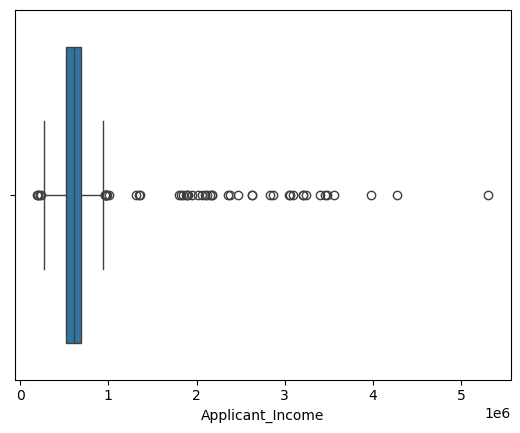

In [28]:
import seaborn as sns
sns.boxplot(x=loan['Applicant_Income'])

In [29]:
# We can clearly see we have outliers in the variable Applicant Income

In [30]:
Q1 = loan['Applicant_Income'].quantile(0.25)

Q3 = loan['Applicant_Income'].quantile(0.75)

IQR = Q3- Q1

UL = Q3 + (1.5 * IQR)

LL = Q1 - (1.5 * IQR)

print(UL,LL)

951926.5 263256.5


In [31]:
outliers_right = loan[loan['Applicant_Income']>UL]
len(outliers_right)

44

In [34]:
outliers_left = loan[loan['Applicant_Income']<LL]
len(outliers_left)

5

In [35]:
all_outliers = loan[(loan['Applicant_Income']>UL)|(loan['Applicant_Income']<LL)]

In [36]:
len(all_outliers)

49

##### We can finally say there are 49 Outliers using IQR method

<a id="zscore"></a>
####  Based on Z-score

Z-score of a value is the difference between that value and the mean, divided by the standard deviation. If the z-score greater than 3 or less than -3, indicates an outlier value. This method is useful when the data distribution is normal. 

This method has a disadvantage that the values of mean and standard deviation are highly affected by the presence of outliers.

In [37]:
x = loan['Applicant_Income']
mu = loan['Applicant_Income'].mean()
sigma = loan['Applicant_Income'].std()
loan['zscore_income'] = (x - mu)/sigma 

In [38]:
right_side_outliers = loan[loan['zscore_income'] > 3]

In [39]:
len(right_side_outliers)

27

In [40]:
left_side_outliers = loan[loan['zscore_income'] < -3]

In [41]:
len(left_side_outliers)

0

In [42]:
all_outliers = loan[(loan['zscore_income']>3)|(loan['zscore_income']<-3)]

In [43]:
len(all_outliers)

27

##### We can finally say there are 27 Outliers using z_score method

### Handling/Treating Outliers

##### Capping / Flooring (Winsorization):
Capping (or Winsorization) is a method where extreme outlier values are replaced by boundary (limit) values — instead of removing them completely.This keeps the data size the same but reduces the influence of extreme values.

In [44]:
Q1 = loan['Applicant_Income'].quantile(0.25)

Q3 = loan['Applicant_Income'].quantile(0.75)

IQR = Q3- Q1

UL = Q3 + (1.5 * IQR)

LL = Q1 - (1.5 * IQR)

print(LL,UL)

# Step 2: Cap values using clip
loan['Applicant_Income_capping'] = loan['Applicant_Income'].clip(lower=LL, upper=UL)

263256.5 951926.5


<Axes: xlabel='Applicant_Income_capping'>

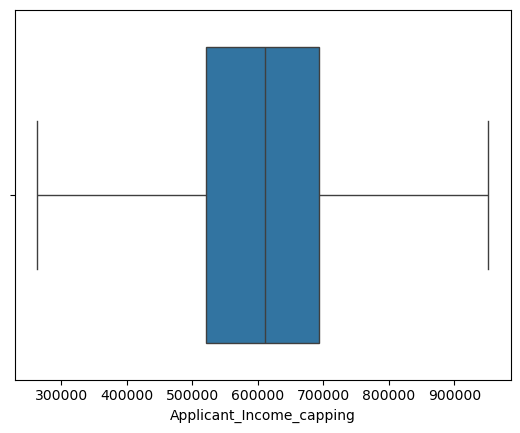

In [45]:
sns.boxplot(x = loan['Applicant_Income_capping'])

In [46]:
len(loan[loan['Applicant_Income_capping']==UL])

44

In [47]:
len(loan[loan['Applicant_Income_capping']==LL])

5

##### Transformation Methods:
Transformation means applying a mathematical function to the data to reduce the effect of outliers and make the distribution more normal or symmetric.

In [48]:
#### Log Transformation 

<Axes: xlabel='Applicant_Income', ylabel='Count'>

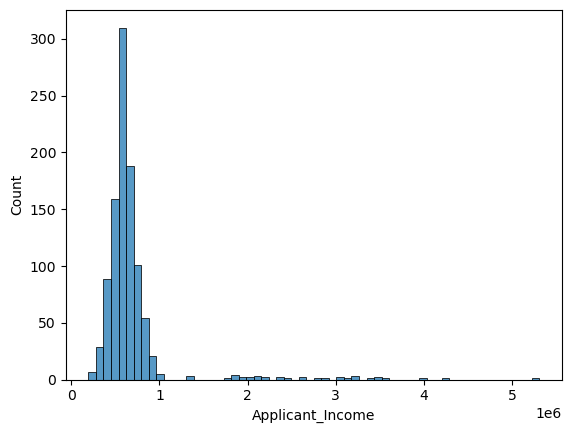

In [49]:
sns.histplot(loan['Applicant_Income'],bins=60)

In [50]:
loan['log_applicant_income'] = np.log(loan['Applicant_Income'])

<Axes: xlabel='log_applicant_income', ylabel='Count'>

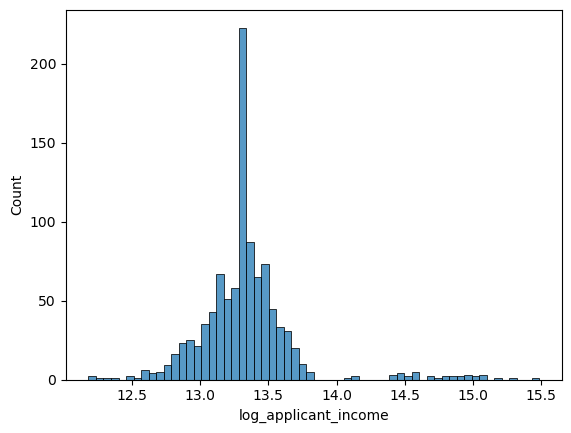

In [51]:
import seaborn as sns 
sns.histplot(loan['log_applicant_income'],bins=60)

In [53]:
# We can clearly see the distribution has become some what better minimizing the impact of outliers.

##### Binning (Grouping Method): 
Binning converts continuous numerical data into categorical groups or intervals, which helps reduce the impact of extreme values.

In [54]:
# Step 1: Calculate quartiles

Q1 = loan['Applicant_Income'].quantile(0.25)
Q2 = loan['Applicant_Income'].quantile(0.50)
Q3 = loan['Applicant_Income'].quantile(0.75)

# Step 2: Create bins based on quartiles
bins = [0, Q1, Q3, float('inf')]   # (0 to Q1) → Low, (Q1 to Q3) → Medium, (Q3 to Infinity) → High
labels = ['Low', 'Medium', 'High']

# Step 3: Apply binning
loan['Applicant_Income_binning'] = pd.cut(loan['Applicant_Income'], bins=bins, labels=labels)

In [55]:
loan['Applicant_Income_binning'].value_counts()

Applicant_Income_binning
Medium    500
Low       250
High      250
Name: count, dtype: int64

##### Removal (Deletion Method):
This is the simplest technique, where rows containing outliers are removed from the dataset.

In [56]:
Q1 = loan['Applicant_Income'].quantile(0.25)

Q3 = loan['Applicant_Income'].quantile(0.75)

IQR = Q3- Q1

UL = Q3 + (1.5 * IQR)

LL = Q1 - (1.5 * IQR)

non_outliers_data = loan[(loan['Applicant_Income']>LL) & (loan['Applicant_Income']<UL)]
non_outliers_data.shape

(951, 15)

In [57]:
loan.shape  # total data 

(1000, 15)

In [58]:
len(loan[(loan['Applicant_Income']<LL) | (loan['Applicant_Income']>UL)])  # 49 outliers

49

In [59]:
len(loan[(loan['Applicant_Income']>=LL) & (loan['Applicant_Income']<=UL)]) # 951 non outliers

951

##### Separate Modeling (Keep Outliers):
Sometimes, outliers are genuine and meaningful observations (e.g.,Big Billion days, fraud cases, VIP customers, rare diseases). In such cases, instead of removing them, they are analyzed or modeled separately.

<a id="cat"> </a>
###  Encoding Techniques (Handle Non-Numeric Data)

The data may contain numerical as well as categorical variables. Machine learning algorithms are designed to work with numerical data.
Thus, it is necessary to convert the categorical variables into a numeric type. The process of converting Numerical data to Categorical data is called Encoding. Different techniques are available to perform such conversion.

##### Dummy Encoder :
Dummy Encoding is a technique that converts each category into a binary (0 or 1) column, but it drops one column to avoid multicollinearity (known as the dummy variable trap).

In [60]:
loan['Gender_Dummy_Encoded'] = pd.get_dummies(loan['Gender'],drop_first=True,dtype='int')

In [61]:
loan[['Gender_Dummy_Encoded','Gender']].head()

,Gender_Dummy_Encoded,Gender
0,0,Female
1,1,Male
2,1,Male
3,0,Female
4,0,Female


In [62]:
loan_cat = loan.select_dtypes(exclude=np.number)
loan_cat.head(1)

,Loan_Status,Gender,Dependents,Marriage_Status,Occupation,Credit_Score,Applicant_Income_binning
0,Yes,Female,Yes,Yes,Business,Medium,Medium


In [63]:
encoded_cat_data = pd.get_dummies(loan_cat,drop_first=True,dtype='int')

In [64]:
encoded_cat_data.head(3)

,Loan_Status_Yes,Gender_Male,Dependents_Yes,Marriage_Status_Yes,Occupation_Job,Credit_Score_Low,Credit_Score_Medium,Applicant_Income_binning_Medium,Applicant_Income_binning_High
0,1,0,1,1,0,0,1,1,0
1,1,1,0,1,1,0,0,1,0
2,0,1,1,0,1,0,1,0,1


##### One Hot Encoder:
One-Hot Encoding converts each categorical value into a new binary column (0 or 1) for every unique category — no column is dropped.

In [67]:
from sklearn.preprocessing import OneHotEncoder

OHE = OneHotEncoder(sparse_output=False)
encoded_array = OHE.fit_transform(loan[['Credit_Score']])
ohe_credit_score = pd.DataFrame(encoded_array, columns=OHE.get_feature_names_out(['Credit_Score']))
ohe_credit_score.head(3)

,Credit_Score_High,Credit_Score_Low,Credit_Score_Medium
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,0.0,1.0


In [68]:
loan = pd.concat([loan,ohe_credit_score],axis=1)
loan.head(3)

,Unnamed: 0,Loan_Status,Applicant_Income,Loan_Amount,Loan_Tenure,Gender,Dependents,Marriage_Status,Occupation,Credit_Score,DOB,zscore_income,Applicant_Income_capping,log_applicant_income,Applicant_Income_binning,Gender_Dummy_Encoded,Credit_Score_High,Credit_Score_Low,Credit_Score_Medium
0,0,Yes,674507.0,122980,15,Female,Yes,Yes,Business,Medium,1976,-0.005771,674507.0,13.421737,Medium,0,0.0,0.0,1.0
1,1,Yes,579260.0,111180,10,Male,No,Yes,Job,High,1974,-0.225729,579260.0,13.269507,Medium,1,1.0,0.0,0.0
2,2,No,697153.0,93364,5,Male,Yes,No,Job,Medium,1990,0.046526,697153.0,13.454760,High,1,0.0,0.0,1.0


##### Ordinal Encoder:
Ordinal Encoding assigns integer values to categories based on their order or ranking. Used when categories have a logical or natural order.

In [69]:
loan['Credit_Score'].value_counts()

Credit_Score
Medium    491
High      291
Low       218
Name: count, dtype: int64

In [70]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(categories=[['Low', 'Medium', 'High']])

# Step 3: Fit and transform
loan['Credit_Score_Ordinal_Encoded'] = encoder.fit_transform(loan[['Credit_Score']])

loan[['Credit_Score_Ordinal_Encoded','Credit_Score']]

,Credit_Score_Ordinal_Encoded,Credit_Score
0,1.0,Medium
1,2.0,High
2,1.0,Medium
3,2.0,High
4,0.0,Low
...,...,...
995,1.0,Medium
996,2.0,High
997,0.0,Low
998,1.0,Medium


##### Label Encoder: 
Label Encoding converts each category into a unique numeric code (0, 1, 2, …) — without considering any order(follows alphabetical order).

In [71]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

# Step 3: Fit and transform
loan['Credit_Score_Label_Encoded'] = encoder.fit_transform(loan['Credit_Score'])

loan[['Credit_Score_Label_Encoded','Credit_Score']].head(3)

,Credit_Score_Label_Encoded,Credit_Score
0,2,Medium
1,0,High
2,2,Medium


##### Frequency Encoder:
Frequency Encoding replaces each category with the frequency or count of how often it appears in the dataset.

In [72]:
freq = loan['Credit_Score'].value_counts(normalize=True)
freq

Credit_Score
Medium    0.491
High      0.291
Low       0.218
Name: proportion, dtype: float64

In [73]:
loan['Credit_Score_Freq'] = loan['Credit_Score'].map(freq)

In [74]:
loan[['Credit_Score_Freq','Credit_Score']].head(3)

,Credit_Score_Freq,Credit_Score
0,0.491,Medium
1,0.291,High
2,0.491,Medium


### Scaling 

Scaling is the process of adjusting the range or magnitude of numerical features so that they are on a similar scale.
It ensures that no single feature dominates others due to large numerical differences.

In simple words —

Scaling brings all numerical values into a common range without changing the shape of the data distribution.

Many machine learning algorithms (like KNN, SVM, Gradient Descent, PCA) are distance-based or gradient-based.
If features have very different ranges (like Age in years and Salary in lakhs), models may give more weight to larger numbers.
Scaling solves this problem by normalizing or standardizing the values.

##### Types of Feature Scaling: There are several methods, but the two most common and widely used are:

##### Standardization (Standard Scaler): 
Standardization transforms the data so that it has a mean = 0 and a standard deviation = 1.
It centers the data around zero by removing the mean and scaling it to unit variance.

In [75]:
from sklearn.preprocessing import StandardScaler

SS = StandardScaler()
loan['Scaled Applicant Income'] = SS.fit_transform(loan[['Applicant_Income']])

In [76]:
print('Mean of Scaled Applicant Income',np.round(loan['Scaled Applicant Income'].mean()))

Mean of Scaled Applicant Income -0.0


In [77]:
print('Standard Deviation of Scaled Applicant Income',np.round(loan['Scaled Applicant Income'].std()))

Standard Deviation of Scaled Applicant Income 1.0


##### Normalization (Min–Max Scaler): 
Normalization (also called Min–Max Scaling) transforms data to a fixed range, usually 0 to 1 (or sometimes –1 to 1).

In [78]:
from sklearn.preprocessing import MinMaxScaler
MM = MinMaxScaler()
loan['min_max_applicant_income'] = MM.fit_transform(loan[['Applicant_Income']])

In [79]:
loan['min_max_applicant_income'].max()

1.0

In [80]:
loan['min_max_applicant_income'].min()

0.0

## Transformation: 
Data Transformation is the process of applying mathematical functions to change the scale, shape, or distribution of data values —
so that the data becomes more suitable for analysis or modeling.

It helps to:

Reduce skewness (make data more symmetric)

Handle outliers

Make data closer to a normal distribution

##### Log Transformation: 
Applies the natural logarithm (or log base 10) to reduce right skewness and compress large values. In general log values follow normal distribution.

In [81]:
loan['log_applicant_income'] = np.log(loan['Applicant_Income'])

<Axes: xlabel='log_applicant_income', ylabel='Count'>

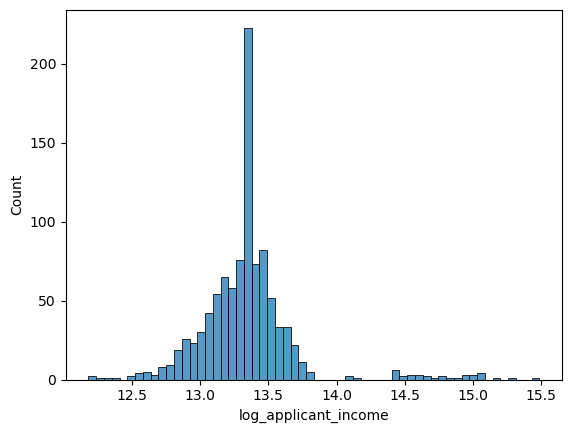

In [82]:
sns.histplot(loan['log_applicant_income'])

##### Exponential Transformation: 
Applies an exponential function to each data value.
Used to reverse the effect of a log transform or to expand small differences.

In [83]:
loan['log_applicant_income'].head(3)

0    13.421737
1    13.269507
2    13.454760
Name: log_applicant_income, dtype: float64

In [84]:
loan['exp_applicant_income'] = np.exp(loan['log_applicant_income'])
loan['exp_applicant_income'].head(3)

0    674507.0
1    579260.0
2    697153.0
Name: exp_applicant_income, dtype: float64

##### Square Root Transformation: 
Takes the square root of each data value to reduce moderate skewness.

In [85]:
loan['square_applicant_income'] = np.square(loan['Applicant_Income'])

<Axes: xlabel='square_applicant_income', ylabel='Count'>

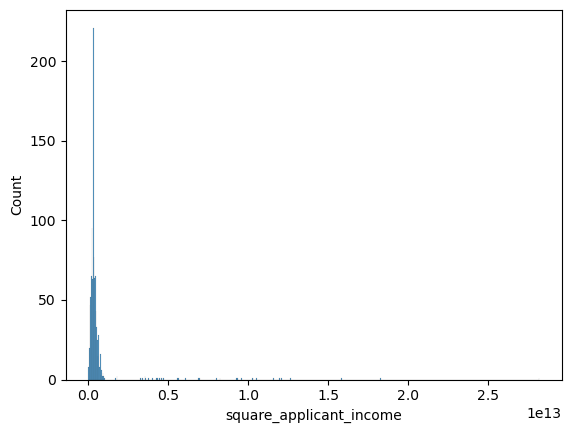

In [86]:
sns.histplot(loan['square_applicant_income'])

#### Power Transformers: 

##### Box-Cox Transformation: 
A specific type of power transformation that helps normalize non-normal data.
It can stabilize variance and reduce skewness — but only works for positive values

##### Yeo-Johnson Transformation:
An improved version of Box–Cox, which can handle zero and negative values as well.
It automatically finds the best λ (lambda) to make the data more normal.

In [87]:
from sklearn.preprocessing import PowerTransformer

In [88]:
PT_box_cox = PowerTransformer(method='box-cox')
loan['Applicant_Income_box_cox'] = PT_box_cox.fit_transform(loan[['Applicant_Income']])

<Axes: xlabel='Applicant_Income_box_cox', ylabel='Count'>

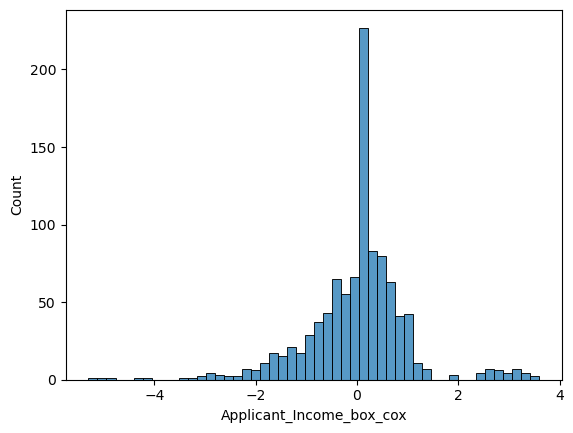

In [89]:
sns.histplot(loan['Applicant_Income_box_cox'])

In [90]:
PT_YJ = PowerTransformer(method='yeo-johnson')
loan['Applicant_Income_YJ'] = PT_YJ.fit_transform(loan[['Applicant_Income']])

<Axes: xlabel='Applicant_Income_YJ', ylabel='Count'>

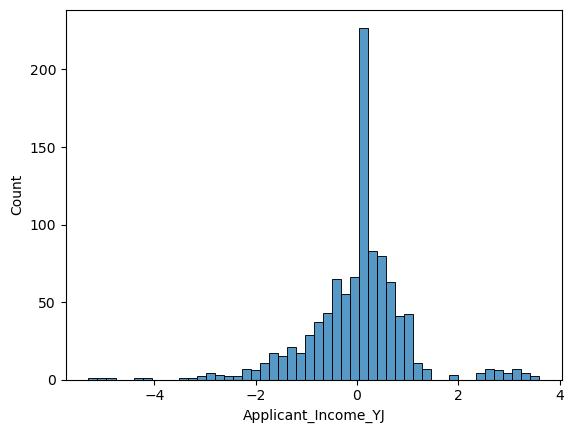

In [91]:
sns.histplot(loan['Applicant_Income_YJ'])

### Feature Engineering

Feature Engineering is the process of creating, modifying, or transforming input variables (features) in a dataset to improve the performance of a machine learning model.

In simple words —

It’s the art of turning raw data into meaningful features that help a model learn patterns better.

#### Feature Creation (Deriving New Features)

Creating new features from existing ones that may provide additional insight to the model.

Examples:

From Date of Birth, derive Age

From Sales and Cost, derive Profit Margin = (Sales – Cost)/Sales

In [92]:
current_year = 2025

In [93]:
loan['age'] = current_year - loan['DOB']

In [94]:
loan['age']

0      49
1      51
2      35
3      52
4      52
       ..
995    39
996    35
997    51
998    54
999    33
Name: age, Length: 1000, dtype: int64

**Feature Transformation, Feature Scaling, Feature Encoding all these are some sort of Feature Engineering types.** 